# SoftAdapt diagnostics for 1-D compressible Navier–Stokes

This Kaggle-ready standalone notebook applies the same local SoftAdapt diagnostic used in the simple-PDE notebook to the periodic one-dimensional compressible Navier–Stokes PINN. The network predicts primitive variables $(\rho,u,p)$ and is trained with three objectives:

1. initial-condition loss (`ics`);
2. periodic value-and-derivative boundary loss (`bcs`);
3. mass, momentum, and total-energy residual loss (`res`).

At every adaptation interval it records component losses, raw and weighted parameter-gradient norms, normalized SoftAdapt scores, selected weights, total-gradient norm, and held-out relative $L_2$ errors. It uses the repository's generated smooth-flow data and `NavierStokesPINN`; all output is local and W&B is not imported.

## Kaggle usage

Import this notebook into Kaggle, enable Internet for the first run so the repository can be cloned, optionally select a GPU accelerator, and choose **Run all**. The setup cell locates an existing checkout or clones it into `/kaggle/working`. If the reference dataset is absent, the notebook generates it locally. No Kaggle secrets or W&B account are needed.

In [1]:
from pathlib import Path
import csv
import os
import subprocess
import sys

PROJECT_NAME = "weight-vs-loss-convergence-pinn"
REPOSITORY_URL = "https://github.com/nthday-jpg/weight-vs-loss-convergence-pinn.git"

# Locate a local checkout. A notebook imported directly into Kaggle normally
# starts in /kaggle/working and therefore uses the clone branch below.
working_directory = Path.cwd().resolve()
candidates = (
    working_directory,
    working_directory / PROJECT_NAME,
    working_directory.parent,
    Path("/kaggle/working") / PROJECT_NAME,
)
ROOT = next((path for path in candidates if (path / "balancer").is_dir()), None)

if ROOT is None:
    clone_parent = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else working_directory
    ROOT = clone_parent / PROJECT_NAME
    print(f"Cloning {REPOSITORY_URL} into {ROOT} ...")
    subprocess.run(
        ["git", "clone", "--depth", "1", REPOSITORY_URL, str(ROOT)],
        check=True,
    )

os.chdir(ROOT)
for path in (ROOT, ROOT / "navier-stokes"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import matplotlib.pyplot as plt
import numpy as np
import torch

from balancer import SoftAdaptBalancer
from model import NavierStokesPINN

SEED = 7
STEPS = 600
BATCH_SIZE = 128
ADAPT_EVERY = 10
LEARNING_RATE = 1e-3
BETA = 1.0
HISTORY_LENGTH = 5
TRAIN_TIME_FRACTION = 0.7
LAYERS = [2, 32, 32, 32, 3]

np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"repository={ROOT}")
print(f"device={device}; steps={STEPS}; adapt every={ADAPT_EVERY}")

repository=D:\MyML\weight-vs-loss-convergence-pinn
device=cpu; steps=600; adapt every=10


## Load the reference solution and construct PINN constraints

The reference trajectory is used for the initial condition, physical constants, and evaluation only. No interior solution observations are included in the optimizer loss. The periodic grid omits the repeated right endpoint, so the right boundary is reconstructed as `x[-1] + dx`.

In [2]:
data_path = ROOT / "navier-stokes" / "data" / "navier_stokes_1d.npz"
if not data_path.exists():
    print("Reference data not found; generating the smooth periodic case ...")
    subprocess.run(
        [
            sys.executable,
            str(ROOT / "navier-stokes" / "data" / "gen_data.py"),
            "--save_dir", str(data_path.parent),
            "--base_name", data_path.stem,
            "--flow_case", "smooth",
            "--spatial_scheme", "central",
            "--nx", "256",
            "--steps", "200",
            "--t_final", "0.6",
            "--mu", "1e-2",
        ],
        cwd=ROOT,
        check=True,
    )
source = np.load(data_path)
data = {
    name: torch.as_tensor(source[name], dtype=torch.float32)
    for name in ("t", "x", "rho", "u", "p")
}
constants = {
    name: float(source[name])
    for name in ("mu", "gamma", "prandtl", "gas_constant")
}

t_end = float(data["t"][-1]) * TRAIN_TIME_FRACTION
x_start = float(data["x"][0])
dx = float(data["x"][1] - data["x"][0])
x_end = float(data["x"][-1]) + dx
train_time_indices = torch.where(data["t"] <= t_end)[0]

ics = {
    "t": torch.zeros_like(data["x"], device=device),
    "x": data["x"].to(device),
    "rho": data["rho"][0].to(device),
    "u": data["u"][0].to(device),
    "p": data["p"][0].to(device),
}
boundary_t = data["t"][train_time_indices].to(device)
bcs = {
    "t": boundary_t,
    "x_left": torch.full_like(boundary_t, x_start),
    "x_right": torch.full_like(boundary_t, x_end),
}

# Fixed, held-out interior points for inexpensive progress evaluation.
generator = torch.Generator().manual_seed(SEED + 1)
eval_time_indices = train_time_indices[1:]
eval_space_indices = torch.arange(1, len(data["x"]))
flat_candidates = len(eval_time_indices) * len(eval_space_indices)
eval_flat = torch.randperm(flat_candidates, generator=generator)[:2048]
eval_t_idx = eval_time_indices[eval_flat // len(eval_space_indices)]
eval_x_idx = eval_space_indices[eval_flat % len(eval_space_indices)]
eval_inputs = {
    "t": data["t"][eval_t_idx].to(device),
    "x": data["x"][eval_x_idx].to(device),
}
eval_targets = {
    name: data[name][eval_t_idx, eval_x_idx].to(device)
    for name in ("rho", "u", "p")
}
print(f"data={data_path.relative_to(ROOT)}; training time=[0, {t_end:.3f}]")
print(f"IC points={len(ics['x'])}; boundary times={len(boundary_t)}; evaluation points={len(eval_flat)}")

data=navier-stokes\data\navier_stokes_1d.npz; training time=[0, 0.420]
IC points=256; boundary times=141; evaluation points=2048


## Diagnostics

The score is the normalized finite-difference slope of each interval-mean loss. For component $i$,

$$
s_i=\frac{\dot{c}^{\mathsf T}\mathbf L_i}{\sum_j|\dot{c}^{\mathsf T}\mathbf L_j|+\epsilon},
\qquad w_i=\operatorname{softmax}(\beta s_i).
$$

Scores are `NaN` until the five-interval history is full. Component gradient norms are evaluated on the final batch of each interval before the optimizer backward pass.

In [3]:
NAMES = ("ics", "bcs", "res")


def parameter_gradient_norm(loss, model):
    gradients = torch.autograd.grad(
        loss, tuple(model.parameters()), retain_graph=True, allow_unused=True
    )
    squared_norm = sum(
        gradient.detach().square().sum()
        for gradient in gradients
        if gradient is not None
    )
    return float(squared_norm.sqrt().cpu())


def softadapt_scores(balancer):
    if not balancer._history_is_full():
        return {name: float("nan") for name in balancer.history}
    slopes = {
        name: float(np.dot(balancer._slope_weights, np.asarray(values)))
        for name, values in balancer.history.items()
    }
    if not balancer.normalized:
        return slopes
    scale = sum(abs(value) for value in slopes.values()) + balancer.epsilon
    return {name: value / scale for name, value in slopes.items()}


@torch.no_grad()
def evaluation_errors(model):
    predictions = model.u_net(eval_inputs["t"], eval_inputs["x"])
    errors = {
        name: float((torch.linalg.vector_norm(prediction - eval_targets[name]) /
                     torch.linalg.vector_norm(eval_targets[name])).cpu())
        for name, prediction in zip(("rho", "u", "p"), predictions)
    }
    errors["mean"] = sum(errors.values()) / 3.0
    return errors

## Train and update SoftAdapt

The weights stored on each row are the newly selected weights, used beginning with the next optimizer step. Accordingly, `*_weighted_grad_norm` shows how the update would scale the just-measured component gradient. `total_grad_norm` is the actual balanced gradient used on that update step, before the new weights are selected.

In [4]:
model = NavierStokesPINN(LAYERS, **constants).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
balancer = SoftAdaptBalancer(
    beta=BETA,
    history_length=HISTORY_LENGTH,
    normalized=True,
    loss_weighted=False,
)

records = []
interval_sums = {name: 0.0 for name in NAMES}
interval_count = 0

for step in range(1, STEPS + 1):
    batch = {
        "t": torch.rand(BATCH_SIZE, device=device) * t_end,
        "x": x_start + torch.rand(BATCH_SIZE, device=device) * (x_end - x_start),
    }
    losses = model(batch, ics, bcs, loss_names=NAMES)
    total_loss = balancer(losses)
    should_adapt = step % ADAPT_EVERY == 0 or step == STEPS

    if should_adapt:
        raw_gradients = {
            name: parameter_gradient_norm(losses[f"{name}_loss"], model)
            for name in NAMES
        }
        total_gradient = parameter_gradient_norm(total_loss, model)

    optimizer.zero_grad(set_to_none=True)
    total_loss.backward()
    optimizer.step()

    interval_count += 1
    for name in NAMES:
        interval_sums[name] += float(losses[f"{name}_loss"].detach().cpu())

    if should_adapt:
        averages = {name: value / interval_count for name, value in interval_sums.items()}
        balancer.update({f"{name}_loss": value for name, value in averages.items()})
        scores = softadapt_scores(balancer)
        errors = evaluation_errors(model)
        record = {
            "step": step,
            "mean_relative_l2": errors["mean"],
            "rho_relative_l2": errors["rho"],
            "u_relative_l2": errors["u"],
            "p_relative_l2": errors["p"],
            "total_grad_norm": total_gradient,
        }
        for name in NAMES:
            record.update({
                f"{name}_loss": averages[name],
                f"{name}_grad_norm": raw_gradients[name],
                f"{name}_weighted_grad_norm": balancer.weights[name] * raw_gradients[name],
                f"{name}_weight": balancer.weights[name],
                f"{name}_score": scores[name],
            })
        records.append(record)
        interval_sums = {name: 0.0 for name in NAMES}
        interval_count = 0

print(f"updates recorded: {len(records)}")
print(f"final mean relative L2: {records[-1]['mean_relative_l2']:.3e}")
print("final weights:", {name: round(value, 4) for name, value in balancer.weights.items()})

updates recorded: 60
final mean relative L2: 5.257e-01
final weights: {'ics': 0.1847, 'bcs': 0.4828, 'res': 0.3325}


In [5]:
output_dir = ROOT / "results" / "softadapt_compressible_ns"
output_dir.mkdir(parents=True, exist_ok=True)
csv_path = output_dir / "diagnostics.csv"
with csv_path.open("w", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=records[0].keys())
    writer.writeheader()
    writer.writerows(records)
print(f"saved {csv_path.relative_to(ROOT)}")

saved results\softadapt_compressible_ns\diagnostics.csv


## Loss, gradient, score, weight, and error histories

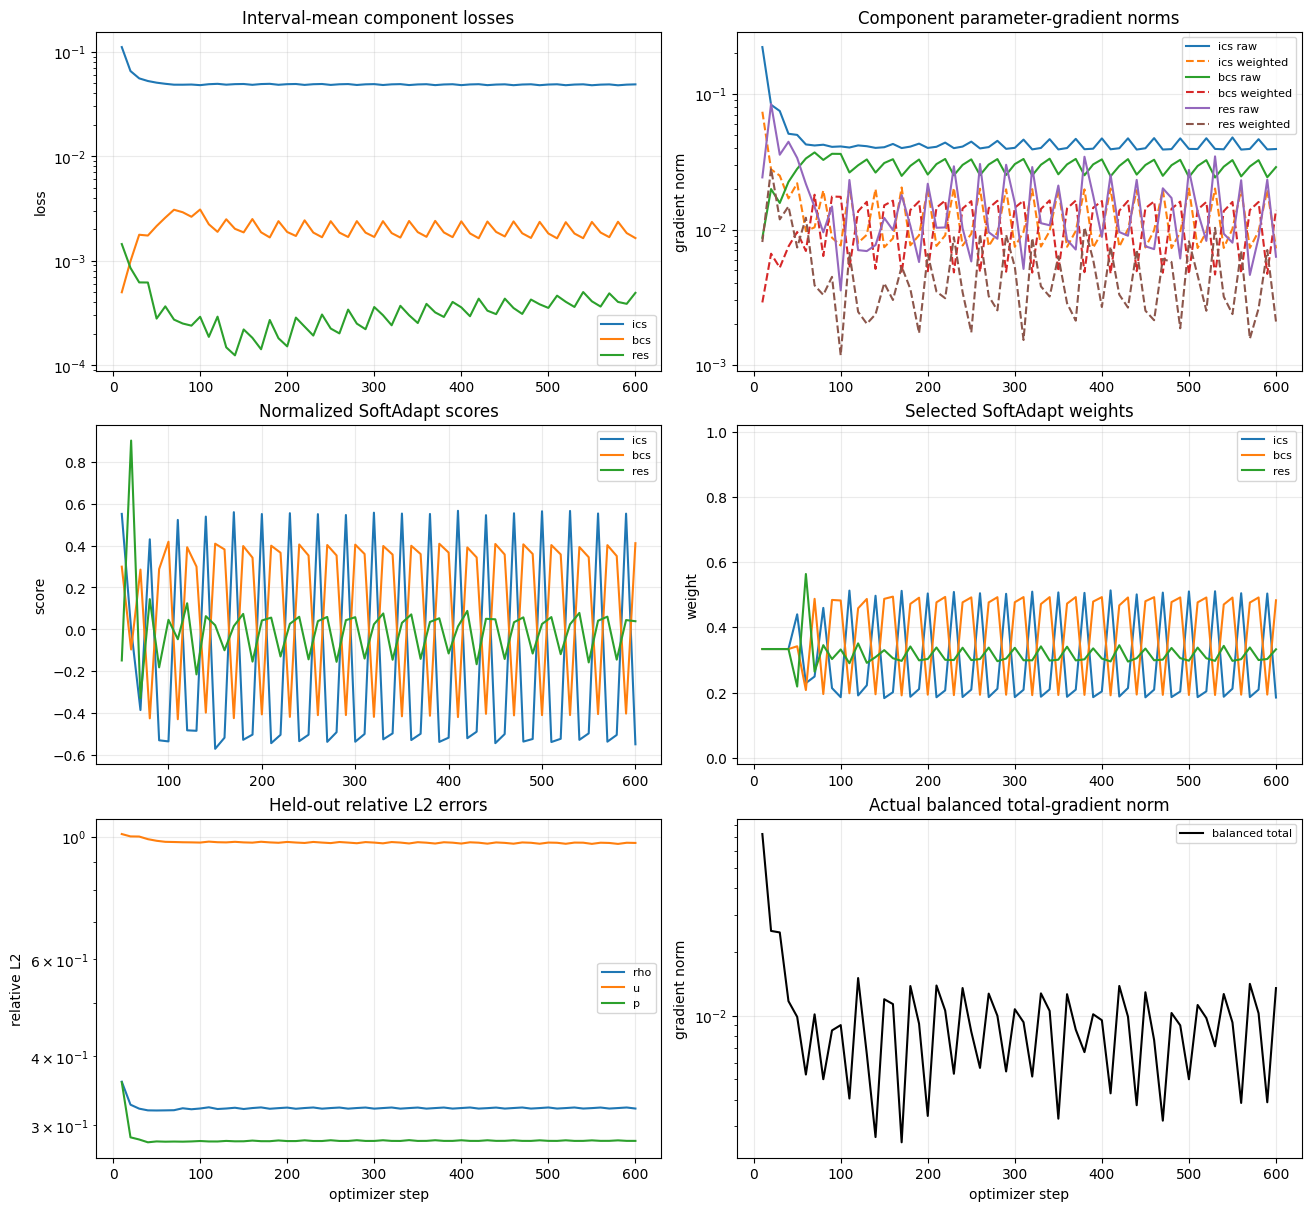

In [6]:
steps = np.asarray([row["step"] for row in records])
fig, axes = plt.subplots(3, 2, figsize=(13, 12), constrained_layout=True)

for name in NAMES:
    axes[0, 0].semilogy(steps, [row[f"{name}_loss"] for row in records], label=name)
    axes[0, 1].semilogy(steps, [row[f"{name}_grad_norm"] for row in records], label=f"{name} raw")
    axes[0, 1].semilogy(steps, [row[f"{name}_weighted_grad_norm"] for row in records], "--", label=f"{name} weighted")
    axes[1, 0].plot(steps, [row[f"{name}_score"] for row in records], label=name)
    axes[1, 1].plot(steps, [row[f"{name}_weight"] for row in records], label=name)
for name in ("rho", "u", "p"):
    axes[2, 0].semilogy(steps, [row[f"{name}_relative_l2"] for row in records], label=name)
axes[2, 1].semilogy(steps, [row["total_grad_norm"] for row in records], color="black", label="balanced total")

axes[0, 0].set(title="Interval-mean component losses", ylabel="loss")
axes[0, 1].set(title="Component parameter-gradient norms", ylabel="gradient norm")
axes[1, 0].set(title="Normalized SoftAdapt scores", ylabel="score")
axes[1, 1].set(title="Selected SoftAdapt weights", ylabel="weight", ylim=(-0.02, 1.02))
axes[2, 0].set(title="Held-out relative L2 errors", ylabel="relative L2", xlabel="optimizer step")
axes[2, 1].set(title="Actual balanced total-gradient norm", ylabel="gradient norm", xlabel="optimizer step")
for ax in axes.flat:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

history_plot = output_dir / "diagnostics.png"
fig.savefig(history_plot, dpi=160)
plt.show()

## Predicted fields at the end of the training-time interval

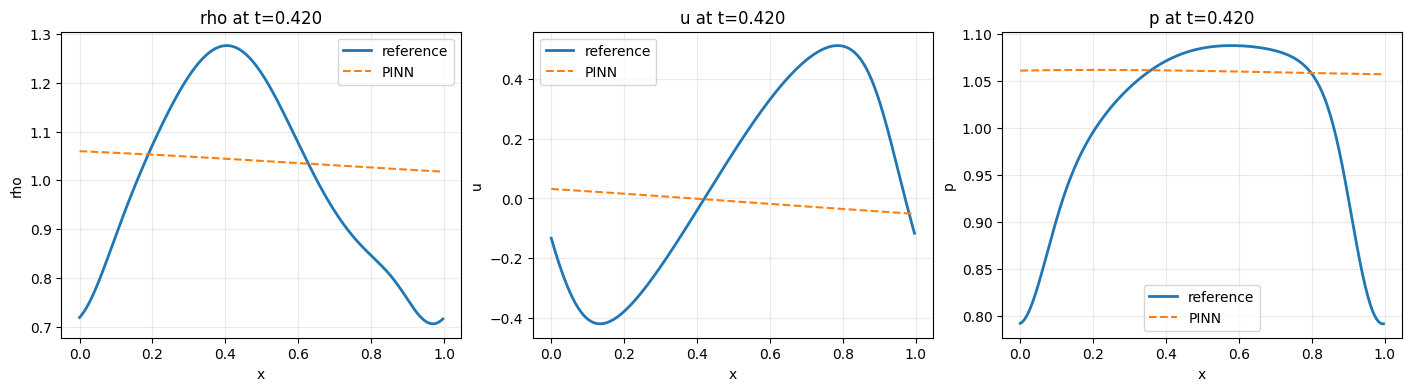

saved plots under results\softadapt_compressible_ns/


In [7]:
time_index = int(train_time_indices[-1])
x_plot = data["x"].to(device)
t_plot = torch.full_like(x_plot, float(data["t"][time_index]))
with torch.no_grad():
    predictions = [value.cpu().numpy() for value in model.u_net(t_plot, x_plot)]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
for ax, name, prediction in zip(axes, ("rho", "u", "p"), predictions):
    ax.plot(data["x"].numpy(), data[name][time_index].numpy(), label="reference", linewidth=2)
    ax.plot(data["x"].numpy(), prediction, "--", label="PINN")
    ax.set(xlabel="x", ylabel=name, title=f"{name} at t={float(data['t'][time_index]):.3f}")
    ax.grid(alpha=0.25)
    ax.legend()
solution_plot = output_dir / "fields.png"
fig.savefig(solution_plot, dpi=160)
plt.show()
print(f"saved plots under {output_dir.relative_to(ROOT)}/")